# 미션 2_호텔 예약 취소 분석

호텔 예약 데이터 **119,390건**에서 예약 취소와 관련된 요인을 찾고, 취소율을 줄이기 위한 실행 방안을 제안합니다.

| 단계 | 내용 |
| :-- | :-- |
| **1. 데이터 품질 점검** | 결측치의 의미 해석, 논리 오류 규칙 10개 점검, 처리 전후 민감도 확인 |
| **2. 탐색적 분석** | 이진·구간·연속형 변수별 취소율 (예약 수와 신뢰구간 함께 표시) |
| **3. 통계 검정** | 카이제곱 + Cramér's V, Mann–Whitney U + Holm 보정 |
| **4. 예측 모델** | 예약 시점 정보만 사용 (데이터 누수 차단), 로지스틱 회귀 vs 랜덤 포레스트 |
| **5. 결론** | 핵심 결과, To Do / Not To Do, 한계 |

**핵심 결과**
- **리드타임**이 가장 강한 신호입니다. 당일 예약은 7%가 취소되지만 1년 이상 전 예약은 68%가 취소되며, 취소 위험은 예약 후 **첫 한 달**에 가장 빠르게 올라갑니다.
- **과거 취소 이력**이 있으면 92%가 다시 취소합니다. 반대로 특별 요청·예약 변경을 **한 번이라도** 한 고객은 취소율이 절반 이하입니다.
- 주차 공간 요청 고객의 취소율이 정확히 0%인 것은 체크인 후 기록되는 **데이터 누수**로 판단해 모델에서 제외했습니다.

### 데이터 구성

| 구분 | 컬럼 |
| :-- | :-- |
| **목표 변수** | `is_canceled` (1 = 취소) |
| **예약 경로** | `hotel`, `market_segment`, `distribution_channel`, `agent`(여행사 ID), `company`(법인 ID) |
| **도착·숙박** | `lead_time`(예약~도착 일수), `arrival_date_*`, `stays_in_weekend_nights`, `stays_in_week_nights` |
| **고객** | `adults`, `children`, `babies`, `country`, `is_repeated_guest`, `previous_cancellations`, `previous_bookings_not_canceled` |
| **요청·변경** | `meal`, `reserved_room_type`, `booking_changes`, `days_in_waiting_list`, `required_car_parking_spaces`, `total_of_special_requests` |
| **결과 이후 정보** ⚠️ | `reservation_status`, `reservation_status_date`, `assigned_room_type`: 취소 여부가 정해진 뒤 기록되므로 원인 분석·예측에서 제외 |

In [1]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib import font_manager
from matplotlib.lines import Line2D
from IPython.display import display
from scipy.stats import chi2_contingency, mannwhitneyu
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay, classification_report, precision_recall_curve, roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 40)
RANDOM_STATE = 42

# 그래프 스타일과 한글 폰트 (Windows · macOS · Linux 순으로 찾음)
sns.set_theme(style="whitegrid")
installed = {f.name for f in font_manager.fontManager.ttflist}
for font in ["Malgun Gothic", "AppleGothic", "NanumGothic"]:
    if font in installed:
        plt.rcParams["font.family"] = font
        break
plt.rcParams["axes.unicode_minus"] = False

BLUE, RED, GRAY = "#2a78d6", "#d03b3b", "#b9b7ae"

In [2]:
raw = pd.read_csv("hotel_data_modified.csv")
print(f"{raw.shape[0]:,}행 × {raw.shape[1]}열")
raw.head(3)

119,390행 × 29열


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,agent,company,days_in_waiting_list,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,NaN,NaN,0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,NaN,NaN,0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,NaN,NaN,0,0,0,Check-Out,2015-07-02


---
## 1. 데이터 품질 점검

### 1-1. 결측치: 지우기 전에 의미부터 해석

In [3]:
missing = raw.isna().sum()
missing = pd.DataFrame({"결측 수": missing, "결측률(%)": (missing / len(raw) * 100).round(2)})
missing[missing["결측 수"] > 0].sort_values("결측 수", ascending=False)

,결측 수,결측률(%)
company,112593,94.31
agent,16340,13.69
country,488,0.41
children,4,0.00


In [4]:
# agent·company 결측이 '모르는 값'인지 '해당 없음'인지: 시장 세그먼트별 결측률로 확인
segment_missing = (
    raw.groupby("market_segment")
    .agg(예약수=("is_canceled", "size"),
         agent_결측률=("agent", lambda s: s.isna().mean() * 100),
         company_결측률=("company", lambda s: s.isna().mean() * 100))
    .sort_values("예약수", ascending=False)
    .round(1)
)
display(segment_missing)
print("ID 0 사용 여부 → agent:", 0 in set(raw["agent"].dropna()), "/ company:", 0 in set(raw["company"].dropna()))
print(f"country 결측 중 Resort Hotel 비율: {raw.loc[raw['country'].isna(), 'hotel'].eq('Resort Hotel').mean():.1%}")

,예약수,agent_결측률,company_결측률
market_segment,,,
Online TA,56477,0.6,99.8
Offline TA/TO,24219,1.6,99.6
Groups,19811,20.9,93.0
Direct,12606,47.7,98.3
Corporate,5295,86.8,15.6
Complementary,743,86.1,57.9
Aviation,237,89.5,10.5
Undefined,2,100.0,100.0


ID 0 사용 여부 → agent: False / company: False
country 결측 중 Resort Hotel 비율: 95.1%


| 컬럼 | 해석 | 처리 |
| :-- | :-- | :-- |
| `agent` | 여행사 채널(Online TA, Offline TA/TO)은 결측이 1% 안팎이고, 직접·법인·항공 예약은 결측이 50~90%입니다. 결측은 **여행사를 거치지 않은 예약**입니다. | 0으로 채우고 `has_agent` 플래그 생성 (ID 0은 원래 없음) |
| `company` | 법인(Corporate)·항공(Aviation)에서만 값이 많습니다. 결측은 **법인 예약이 아님**을 뜻합니다. | 0으로 채우고 `has_company` 플래그 생성 |
| `country` | 결측 488건 중 95%가 Resort Hotel입니다. 특정 집단에 몰려 있어 지우면 편향이 생깁니다. | `Unknown` 범주로 유지 |
| `children` | 4건(0.003%)뿐이고 92.8%가 0명입니다. | 0으로 채움 |

`meal`의 `Undefined`와 `SC`는 모두 "식사 미포함"이라 `SC`로 통일합니다. 완전히 같은 중복 행 3만여 건은 **예약 ID가 없어 같은 조건의 다른 예약**일 수 있으므로 지우지 않습니다.

In [5]:
df = raw.copy()
df["children"] = df["children"].fillna(0).astype(int)
df["country"] = df["country"].fillna("Unknown")
df["has_agent"] = df["agent"].notna().astype(int)
df["has_company"] = df["company"].notna().astype(int)
df[["agent", "company"]] = df[["agent", "company"]].fillna(0).astype(int)
df["meal"] = df["meal"].replace("Undefined", "SC")

# 규칙 점검과 분석에 쓸 날짜·파생 변수
df["arrival_date"] = pd.to_datetime(
    df["arrival_date_year"].astype(str) + "-" + df["arrival_date_month"] + "-" + df["arrival_date_day_of_month"].astype(str),
    format="%Y-%B-%d", errors="coerce",
)
df["status_date"] = pd.to_datetime(df["reservation_status_date"], errors="coerce")
df["total_nights"] = df["stays_in_weekend_nights"] + df["stays_in_week_nights"]
df["total_guests"] = df["adults"] + df["children"] + df["babies"]

assert df[["children", "country", "agent", "company"]].notna().all().all()
print(f"결측 처리 완료 · 중복 행 {raw.duplicated().sum():,}건은 유지")

결측 처리 완료 · 중복 행 33,103건은 유지


### 1-2. 논리 오류: 규칙 10개로 점검

인원 이상치에 IQR 기준을 그대로 쓰면 **정상 예약을 대량으로 오탐**합니다. 대부분의 값이 0~2명에 몰려 IQR 폭이 0이 되기 때문입니다. 그래서 업무 기준(성인 10명 · 어린이 5명 · 아기 5명 초과)을 적용했습니다.

In [6]:
people = df[["adults", "children", "babies"]]
q1, q3 = people.quantile(0.25), people.quantile(0.75)
iqr_fence = q3 + 1.5 * (q3 - q1)
print("IQR 상한:", iqr_fence.to_dict())
print(f"IQR 상한을 넘는 예약: {(people > iqr_fence).any(axis=1).mean():.1%}  ← 이상치로 보기엔 너무 많다")

IQR 상한: {'adults': 2.0, 'children': 0.0, 'babies': 0.0}
IQR 상한을 넘는 예약: 12.6%  ← 이상치로 보기엔 너무 많다


In [7]:
booking_date = df["arrival_date"] - pd.to_timedelta(df["lead_time"], unit="D")
expected_checkout = df["arrival_date"] + pd.to_timedelta(df["total_nights"], unit="D")
status = df["reservation_status"]

# 규칙명: (위반 마스크, 처리, 근거)
rules = {
    "투숙객 0명": (df["total_guests"].eq(0), "제거", "사람이 없는 예약은 성립하지 않음"),
    "성인 없이 아기만 투숙": (df["babies"].gt(0) & df["adults"].eq(0), "제거", "아기 단독 투숙은 불가능"),
    "인원 극단값": (df["adults"].gt(10) | df["children"].gt(5) | df["babies"].gt(5), "제거", "업무 기준(10·5·5명) 초과"),
    "Check-Out인데 확정일 ≠ 체크아웃 예정일": (status.eq("Check-Out") & df["status_date"].ne(expected_checkout), "제거", "상태와 날짜 중 하나가 오류"),
    "No-Show인데 확정일 ≠ 도착일": (status.eq("No-Show") & df["status_date"].ne(df["arrival_date"]), "제거", "노쇼는 도착일에 확정되어야 함"),
    "재방문 플래그 모순": (df["is_repeated_guest"].eq(0) & df["previous_bookings_not_canceled"].gt(0), "보정 (→ 1)", "정상 이용 이력이 있으면 재방문 고객"),
    "대기일수 > 리드타임": (df["days_in_waiting_list"].gt(df["lead_time"]), "-", "대기는 예약~도착 사이에 있어야 함"),
    "상태 확정일 < 예약일": (df["status_date"].lt(booking_date), "-", "예약 전에 상태가 정해질 수 없음"),
    "취소 확정일 > 도착일": (status.eq("Canceled") & df["status_date"].gt(df["arrival_date"]), "-", "도착 후에는 취소가 아닌 노쇼"),
    "존재하지 않는 날짜": (df["arrival_date"].isna() | df["status_date"].isna(), "-", "2월 30일 같은 날짜"),
}

rule_report = pd.DataFrame(
    [{"규칙": name, "위반 건수": int(mask.sum()), "비율(%)": round(mask.mean() * 100, 3), "처리": action, "근거": reason}
     for name, (mask, action, reason) in rules.items()]
)
rule_report

,규칙,위반 건수,비율(%),처리,근거
0,투숙객 0명,180,0.151,제거,사람이 없는 예약은 성립하지 않음
1,성인 없이 아기만 투숙,3,0.003,제거,아기 단독 투숙은 불가능
2,인원 극단값,15,0.013,제거,업무 기준(10·5·5명) 초과
3,Check-Out인데 확정일 ≠ 체크아웃 예정일,27,0.023,제거,상태와 날짜 중 하나가 오류
4,No-Show인데 확정일 ≠ 도착일,1,0.001,제거,노쇼는 도착일에 확정되어야 함
5,재방문 플래그 모순,782,0.655,보정 (→ 1),정상 이용 이력이 있으면 재방문 고객
6,대기일수 > 리드타임,0,0.000,-,대기는 예약~도착 사이에 있어야 함
7,상태 확정일 < 예약일,0,0.000,-,예약 전에 상태가 정해질 수 없음
8,취소 확정일 > 도착일,0,0.000,-,도착 후에는 취소가 아닌 노쇼
9,존재하지 않는 날짜,0,0.000,-,2월 30일 같은 날짜


- **성인 없이 어린이만 있는 예약**(223건)은 어린이 나이 기준이 정의되어 있지 않아 지우지 않았습니다.
- **재방문 플래그 모순**은 행을 지우지 않고 플래그만 1로 고쳤습니다. 과거 정상 이용 횟수는 관측된 사실이지만, 플래그는 갱신이 누락됐을 가능성이 더 크기 때문입니다.

In [8]:
drop_mask = pd.concat([mask for mask, action, _ in rules.values() if action == "제거"], axis=1).any(axis=1)
clean = df.loc[~drop_mask].copy()
clean.loc[clean["previous_bookings_not_canceled"].gt(0), "is_repeated_guest"] = 1

# 재검증: 정제 후에는 모든 규칙 위반이 0건이어야 한다
assert clean["total_guests"].gt(0).all()
assert not (clean["is_repeated_guest"].eq(0) & clean["previous_bookings_not_canceled"].gt(0)).any()
assert not drop_mask.loc[clean.index].any()

print(f"제거 {drop_mask.sum():,}건 · 재방문 플래그 보정 {rules['재방문 플래그 모순'][0].sum():,}건 · 최종 {len(clean):,}행 ({len(clean) / len(df):.2%} 보존)")

제거 225건 · 재방문 플래그 보정 782건 · 최종 119,165행 (99.81% 보존)


In [9]:
# 민감도 확인: 처리 방식에 따라 핵심 지표(취소율)가 달라지는가?
scenarios = {"원본": df, "정제본 (분석 사용)": clean, "중복 행까지 제거 (참고)": df.drop_duplicates(subset=raw.columns)}
pd.DataFrame(
    [{"시나리오": k, "행 수": f"{len(v):,}", "취소율": f"{v['is_canceled'].mean():.2%}"} for k, v in scenarios.items()]
).set_index("시나리오")

,행 수,취소율
시나리오,,
원본,"119,390",37.04%
정제본 (분석 사용),"119,165",37.08%
중복 행까지 제거 (참고),"86,287",27.69%


오류 행을 제거해도 취소율은 거의 같아 **분석 결론에는 영향이 없습니다.** 반면 중복 행을 지우면 취소율이 10%p 가까이 떨어집니다. 예약 ID 없이 중복을 지우면 결과가 크게 왜곡될 수 있다는 근거입니다.

---
## 2. 탐색적 분석

모든 그래프에는 **취소율과 함께 예약 수를 표시**합니다. 예약 수가 적은 범주는 우연히 0% 또는 100%가 나와 중요해 보일 수 있기 때문입니다. 빨간 점선은 전체 취소율입니다.

In [10]:
BASE = clean["is_canceled"].mean()
MIN_N = 500  # 이보다 예약 수가 적은 범주는 취소율을 신뢰하지 않는다


def rate_table(key: pd.Series) -> pd.DataFrame:
    """범주별 예약 수 · 취소율 · 95% 신뢰구간"""
    g = clean.groupby(key, observed=True)["is_canceled"].agg(예약수="size", 취소율="mean")
    se = np.sqrt(g["취소율"] * (1 - g["취소율"]) / g["예약수"])
    g["95% 하한"] = (g["취소율"] - 1.96 * se).clip(0, 1)
    g["95% 상한"] = (g["취소율"] + 1.96 * se).clip(0, 1)
    return g


print(f"전체 예약 {len(clean):,}건 · 취소 {clean['is_canceled'].sum():,}건 · 전체 취소율 {BASE:.1%}")

전체 예약 119,165건 · 취소 44,184건 · 전체 취소율 37.1%


### 2-1. 이진 변수: 있다 vs 없다

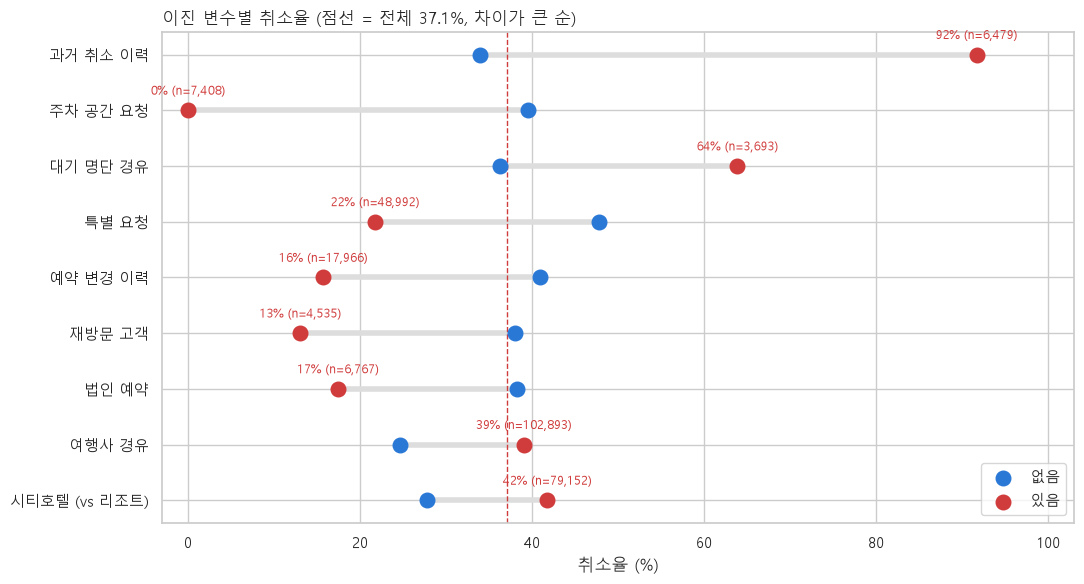

,없음 취소율,있음 취소율,있음 예약수,차이(%p)
변수,,,,
과거 취소 이력,33.9%,91.7%,"6,479",+57.7
주차 공간 요청,39.5%,0.0%,"7,408",-39.5
대기 명단 경유,36.2%,63.9%,"3,693",+27.7
특별 요청,47.8%,21.8%,"48,992",-26.0
예약 변경 이력,40.9%,15.7%,"17,966",-25.1
재방문 고객,38.0%,13.1%,"4,535",-25.0
법인 예약,38.3%,17.5%,"6,767",-20.8
여행사 경유,24.6%,39.0%,"102,893",+14.4
시티호텔 (vs 리조트),27.8%,41.8%,"79,152",+14.0


In [11]:
binary = {
    "시티호텔 (vs 리조트)": clean["hotel"].eq("City Hotel"),
    "재방문 고객": clean["is_repeated_guest"].eq(1),
    "과거 취소 이력": clean["previous_cancellations"].gt(0),
    "예약 변경 이력": clean["booking_changes"].gt(0),
    "여행사 경유": clean["has_agent"].eq(1),
    "법인 예약": clean["has_company"].eq(1),
    "주차 공간 요청": clean["required_car_parking_spaces"].gt(0),
    "특별 요청": clean["total_of_special_requests"].gt(0),
    "대기 명단 경유": clean["days_in_waiting_list"].gt(0),
}
rows = []
for name, flag in binary.items():
    t = rate_table(flag.astype(int))
    rows.append({"변수": name, "없음 취소율": t.loc[0, "취소율"], "있음 취소율": t.loc[1, "취소율"],
                 "있음 예약수": int(t.loc[1, "예약수"]), "차이(%p)": (t.loc[1, "취소율"] - t.loc[0, "취소율"]) * 100})
binary_summary = pd.DataFrame(rows).set_index("변수").sort_values("차이(%p)", key=abs, ascending=False)

# 아령 그래프: 두 점 사이 거리 = 효과 크기
plot_df = binary_summary.iloc[::-1]
y = np.arange(len(plot_df))
fig, ax = plt.subplots(figsize=(11, 6))
ax.hlines(y, plot_df["없음 취소율"] * 100, plot_df["있음 취소율"] * 100, color="#ddd", linewidth=4, zorder=1)
ax.scatter(plot_df["없음 취소율"] * 100, y, s=110, color=BLUE, zorder=3, label="없음")
ax.scatter(plot_df["있음 취소율"] * 100, y, s=110, color=RED, zorder=3, label="있음")
for i, (name, r) in enumerate(plot_df.iterrows()):
    ax.text(r["있음 취소율"] * 100, i + 0.28, f"{r['있음 취소율']:.0%} (n={int(r['있음 예약수']):,})", ha="center", fontsize=8.5, color=RED)
ax.axvline(BASE * 100, color=RED, linestyle="--", linewidth=1)
ax.set_yticks(y, plot_df.index)
ax.set_xlim(-3, 103)
ax.set_xlabel("취소율 (%)")
ax.set_title(f"이진 변수별 취소율 (점선 = 전체 {BASE:.1%}, 차이가 큰 순)", loc="left")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

binary_summary.style.format({"없음 취소율": "{:.1%}", "있음 취소율": "{:.1%}", "있음 예약수": "{:,}", "차이(%p)": "{:+.1f}"})

- **과거 취소 이력**이 있는 고객은 10명 중 9명이 다시 취소합니다. 단일 변수로는 가장 강한 신호입니다.
- **주차 공간 요청** 고객의 취소율은 정확히 0%입니다. 실제 관계라면 이렇게 깨끗한 0%가 나올 수 없습니다. 체크인 시점에 기록되는 값으로 보이며, 취소된 예약은 이 값을 가질 수 없는 **데이터 누수**입니다. 그래서 예측 모델에서 제외합니다.
- **특별 요청·예약 변경**처럼 고객이 예약에 관여한 흔적이 있으면 취소율이 크게 낮아집니다.
- **재방문·법인 예약**처럼 호텔과 직접 관계가 있는 예약은 덜 취소되고, **대기 명단**을 거친 예약은 더 많이 취소됩니다.

### 2-2. 구간별 취소율

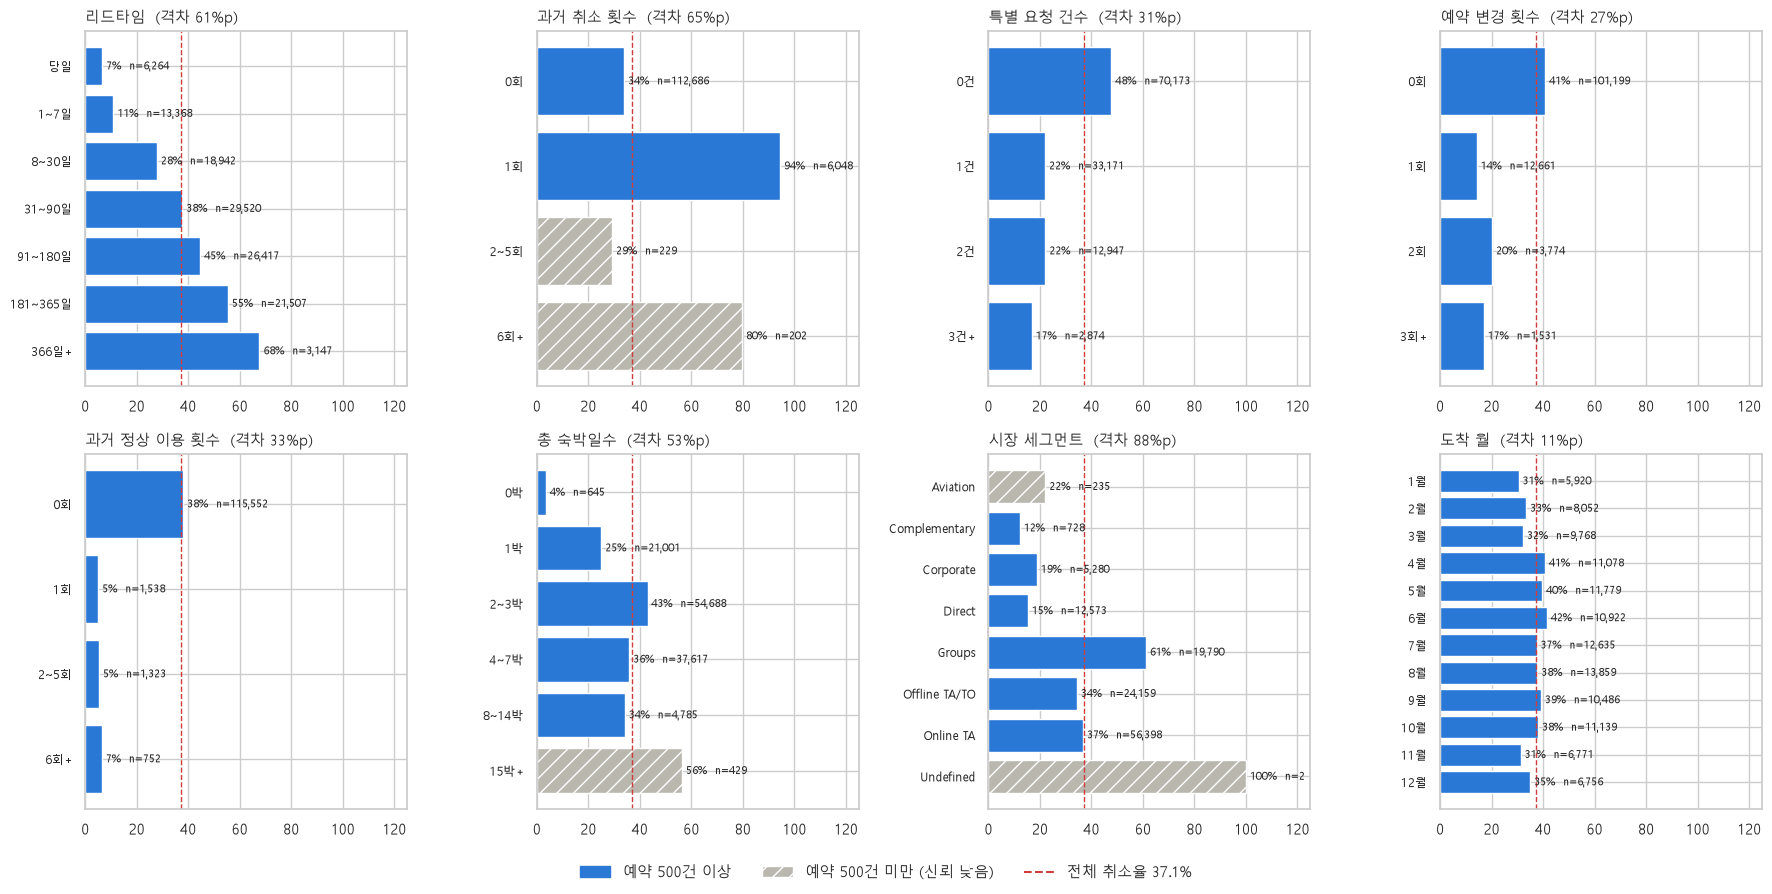

In [12]:
def bins(col, edges, labels):
    return pd.cut(clean[col], bins=edges, labels=labels, include_lowest=True)


MONTHS = ["January", "February", "March", "April", "May", "June", "July", "August", "September", "October", "November", "December"]
grouped = {
    "리드타임": bins("lead_time", [-1, 0, 7, 30, 90, 180, 365, 10**4], ["당일", "1~7일", "8~30일", "31~90일", "91~180일", "181~365일", "366일+"]),
    "과거 취소 횟수": bins("previous_cancellations", [-1, 0, 1, 5, 10**4], ["0회", "1회", "2~5회", "6회+"]),
    "특별 요청 건수": bins("total_of_special_requests", [-1, 0, 1, 2, 10**4], ["0건", "1건", "2건", "3건+"]),
    "예약 변경 횟수": bins("booking_changes", [-1, 0, 1, 2, 10**4], ["0회", "1회", "2회", "3회+"]),
    "과거 정상 이용 횟수": bins("previous_bookings_not_canceled", [-1, 0, 1, 5, 10**4], ["0회", "1회", "2~5회", "6회+"]),
    "총 숙박일수": bins("total_nights", [-1, 0, 1, 3, 7, 14, 10**4], ["0박", "1박", "2~3박", "4~7박", "8~14박", "15박+"]),
    "시장 세그먼트": clean["market_segment"],
    "도착 월": pd.Categorical(clean["arrival_date_month"], categories=MONTHS, ordered=True).rename_categories([f"{i}월" for i in range(1, 13)]),
}
tables = {name: rate_table(pd.Series(key, index=clean.index, name=name)) for name, key in grouped.items()}

fig, axes = plt.subplots(2, 4, figsize=(18, 9))
for ax, (name, t) in zip(axes.ravel(), tables.items()):
    t = t.iloc[::-1]
    thin = t["예약수"] < MIN_N
    bars = ax.barh(t.index.astype(str), t["취소율"] * 100, color=[GRAY if s else BLUE for s in thin])
    for bar, s in zip(bars, thin):
        bar.set_hatch("//" if s else None)
    for i, (rate, n) in enumerate(zip(t["취소율"], t["예약수"])):
        ax.text(rate * 100 + 1.5, i, f"{rate:.0%}  n={n:,}", va="center", fontsize=8)
    ax.axvline(BASE * 100, color=RED, linestyle="--", linewidth=1)
    spread = (t["취소율"].max() - t["취소율"].min()) * 100
    ax.set_title(f"{name}  (격차 {spread:.0f}%p)", loc="left", fontsize=11)
    ax.set_xlim(0, 125)
    ax.tick_params(axis="y", labelsize=8.5)
fig.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=BLUE), plt.Rectangle((0, 0), 1, 1, facecolor=GRAY, hatch="//"),
                    Line2D([], [], color=RED, linestyle="--")],
           labels=[f"예약 {MIN_N}건 이상", f"예약 {MIN_N}건 미만 (신뢰 낮음)", f"전체 취소율 {BASE:.1%}"],
           loc="lower center", ncol=3, frameon=False)
plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.show()

- **리드타임**은 당일 7% → 366일 이상 68%로 **단조 증가**합니다. 모든 구간이 3천 건 이상이라 믿을 수 있는 추세입니다.
- **특별 요청·예약 변경**은 0 → 1로 갈 때 취소율이 절반으로 떨어지고, 그 뒤로는 거의 평평합니다. **많이**가 아니라 **한 번이라도** 하게 만드는 것이 핵심입니다.
- **과거 취소 2~5회**는 29%로 낮아 보이지만 예약 수가 적어(빗금) 판단하지 않습니다. 예약 수를 함께 보지 않으면 잘못된 결론을 내릴 수 있는 예입니다.
- **Groups(단체)** 세그먼트는 취소율이 61%로 가장 높고 예약 수도 많아 우선 관리 대상입니다.
- **도착 월**의 격차는 작습니다. 계절보다 **예약 방식**이 취소를 더 크게 가릅니다.

### 2-3. 리드타임: 취소 위험은 언제 쌓이는가

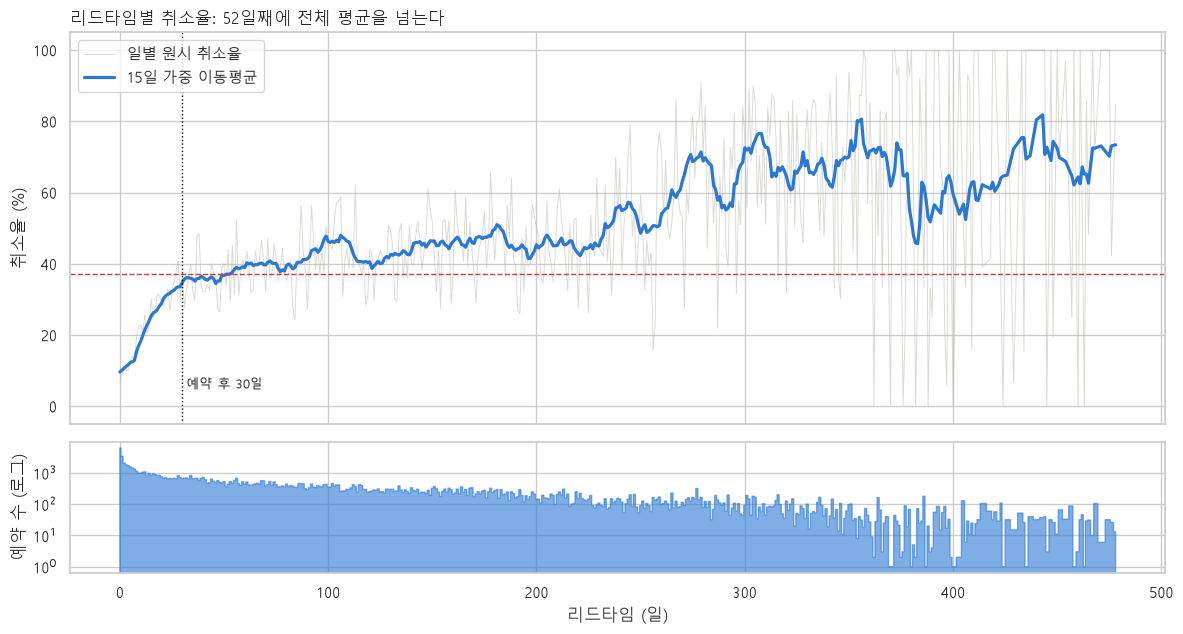

0일 10% → 30일 35% → 300일 73%
첫 30일 기울기: 하루 0.84%p · 30~300일 기울기: 하루 0.14%p


In [13]:
lead = clean.groupby("lead_time")["is_canceled"].agg(n="size", canceled="sum")
lead = lead[lead.index <= clean["lead_time"].quantile(0.995)]
window = 15  # 예약 수로 가중한 이동평균: 예약이 적은 날이 곡선을 흔들지 않는다
lead["smoothed"] = lead["canceled"].rolling(window, center=True, min_periods=1).sum() / lead["n"].rolling(window, center=True, min_periods=1).sum()
first_over = lead.index[(lead["smoothed"] >= BASE)].min()

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
ax1.plot(lead.index, lead["canceled"] / lead["n"] * 100, color=GRAY, linewidth=0.7, alpha=0.5, label="일별 원시 취소율")
ax1.plot(lead.index, lead["smoothed"] * 100, color=BLUE, linewidth=2.3, label=f"{window}일 가중 이동평균")
ax1.axhline(BASE * 100, color=RED, linestyle="--", linewidth=1)
ax1.axvline(30, color="black", linestyle=":", linewidth=1)
ax1.text(32, 5, "예약 후 30일", fontsize=9)
ax1.set_ylabel("취소율 (%)")
ax1.set_title(f"리드타임별 취소율: {first_over}일째에 전체 평균을 넘는다", loc="left")
ax1.legend(loc="upper left")
ax2.fill_between(lead.index, lead["n"], color=BLUE, alpha=0.6, step="mid")
ax2.set_yscale("log")
ax2.set_ylabel("예약 수 (로그)")
ax2.set_xlabel("리드타임 (일)")
plt.tight_layout()
plt.show()

at = {d: lead["smoothed"].asof(d) * 100 for d in [0, 30, 300]}
print(f"0일 {at[0]:.0f}% → 30일 {at[30]:.0f}% → 300일 {at[300]:.0f}%")
print(f"첫 30일 기울기: 하루 {(at[30] - at[0]) / 30:.2f}%p · 30~300일 기울기: 하루 {(at[300] - at[30]) / 270:.2f}%p")

취소율은 **예약 후 첫 30일 동안 하루 약 0.8%p씩 가파르게** 오르고, 그 뒤로는 하루 약 0.14%p로 **약 6분의 1 속도**로 완만해집니다. 따라서 리마인드나 예약 확정 요청 같은 조치는 **예약 후 한 달 안에** 하는 것이 가장 효율적입니다. 400일 이후의 원시 값은 하루 예약이 수십 건뿐이라 크게 흔들리므로 해석하지 않습니다.

---
## 3. 통계 검정: 차이가 우연이 아닌가, 얼마나 큰가

데이터가 10만 건이 넘으면 아주 작은 차이도 p값이 0에 가까워집니다. 그래서 **p값(유의성)과 효과 크기(얼마나 큰가)를 함께** 봅니다.

In [14]:
def cramers_v(table: pd.DataFrame) -> float:
    chi2 = chi2_contingency(table)[0]
    return float(np.sqrt(chi2 / table.to_numpy().sum() / (min(table.shape) - 1)))


categorical_tests = {
    "리드타임 구간": grouped["리드타임"], "시장 세그먼트": clean["market_segment"], "예약 유통 채널": clean["distribution_channel"],
    "특별 요청 건수": grouped["특별 요청 건수"], "과거 취소 횟수": grouped["과거 취소 횟수"], "예약 변경 횟수": grouped["예약 변경 횟수"],
    "호텔 유형": clean["hotel"], "식사 옵션": clean["meal"], "도착 월": clean["arrival_date_month"],
}
chi_rows = []
for name, key in categorical_tests.items():
    table = pd.crosstab(key, clean["is_canceled"])
    chi2, p, dof, _ = chi2_contingency(table)
    chi_rows.append({"변수": name, "카이제곱": chi2, "자유도": dof, "p값": p, "Cramér's V": cramers_v(table)})
chi_result = pd.DataFrame(chi_rows).set_index("변수").sort_values("Cramér's V", ascending=False)
chi_result.style.format({"카이제곱": "{:,.0f}", "p값": "{:.1e}", "Cramér's V": "{:.3f}"}).bar(subset=["Cramér's V"], color="#9ecae1")

,카이제곱,자유도,p값,Cramér's V
변수,,,,
리드타임 구간,"12,121",6,0.0e+00,0.319
과거 취소 횟수,"9,171",3,0.0e+00,0.277
시장 세그먼트,"8,509",7,0.0e+00,0.267
특별 요청 건수,"8,397",3,0.0e+00,0.265
예약 변경 횟수,"4,177",3,0.0e+00,0.187
예약 유통 채널,"3,752",4,0.0e+00,0.177
호텔 유형,"2,243",1,0.0e+00,0.137
도착 월,583,11,7.1e-118,0.070
식사 옵션,231,3,1.0e-49,0.044


In [15]:
def holm(p_values: np.ndarray) -> np.ndarray:
    """Holm 다중비교 보정"""
    order = np.argsort(p_values)
    adjusted = np.empty_like(p_values)
    running = 0.0
    for rank, idx in enumerate(order):
        running = max(running, min((len(p_values) - rank) * p_values[idx], 1.0))
        adjusted[idx] = running
    return adjusted


numeric_tests = ["lead_time", "total_nights", "total_guests", "previous_cancellations",
                 "previous_bookings_not_canceled", "total_of_special_requests", "booking_changes"]
mw_rows = []
for col in numeric_tests:
    canceled, kept = clean.loc[clean["is_canceled"].eq(1), col], clean.loc[clean["is_canceled"].eq(0), col]
    u, p = mannwhitneyu(canceled, kept)
    mw_rows.append({"변수": col, "유지 중앙값": kept.median(), "취소 중앙값": canceled.median(), "p값": p,
                    "효과 크기 (rank-biserial)": 2 * u / (len(canceled) * len(kept)) - 1})
mw_result = pd.DataFrame(mw_rows).set_index("변수")
mw_result["Holm 보정 p값"] = holm(mw_result["p값"].to_numpy())
mw_result = mw_result.sort_values("효과 크기 (rank-biserial)", key=abs, ascending=False)
mw_result.style.format({"유지 중앙값": "{:g}", "취소 중앙값": "{:g}", "p값": "{:.1e}", "Holm 보정 p값": "{:.1e}", "효과 크기 (rank-biserial)": "{:+.3f}"})

,유지 중앙값,취소 중앙값,p값,효과 크기 (rank-biserial),Holm 보정 p값
변수,,,,,
lead_time,45,113,0.0e+00,+0.378,0.0e+00
total_of_special_requests,1,0,0.0e+00,-0.272,0.0e+00
booking_changes,0,0,0.0e+00,-0.137,0.0e+00
previous_cancellations,0,0,0.0e+00,+0.127,0.0e+00
total_guests,2,2,2.4e-66,+0.049,4.8e-66
total_nights,3,3,6.5e-37,+0.043,6.5e-37
previous_bookings_not_canceled,0,0,0.0e+00,-0.041,0.0e+00


- 모든 변수가 Holm 보정 후에도 유의하지만, **효과 크기는 크게 다릅니다.**
- 범주형에서는 **리드타임 구간 · 과거 취소 횟수 · 시장 세그먼트 · 특별 요청 건수**의 관련성이 크고(Cramér's V 0.26~0.32), **도착 월 · 식사 옵션**은 작습니다(0.07 이하).
- 수치형에서는 **리드타임**의 효과 크기가 가장 큽니다(중앙값: 유지 45일 vs 취소 113일). **특별 요청 수**는 반대 방향으로 큽니다.
- 탐색적 분석에서 본 패턴이 우연이 아님을 확인했습니다. 다만 관찰 데이터라 **인과관계는 아닙니다.**

---
## 4. 예측 모델: 예약 시점 정보만으로 취소를 구분할 수 있는가

목적은 최고 성능이 아니라, **여러 변수를 함께 고려해도 주요 패턴이 유지되는지** 확인하는 것입니다. 예약 이후에 생기거나 바뀌는 정보는 모두 제외해 **데이터 누수**를 막았습니다.

| 제외한 변수 | 이유 |
| :-- | :-- |
| `reservation_status`, `reservation_status_date`, `assigned_room_type` | 취소 여부가 정해진 뒤 기록됨 |
| `required_car_parking_spaces` | 주차 요청 고객 취소율 0%: 체크인 시점 정보로 판단 |
| `booking_changes`, `days_in_waiting_list` | 예약 이후에 바뀌는 값 |

In [16]:
numeric_features = ["lead_time", "stays_in_weekend_nights", "stays_in_week_nights", "adults", "children", "babies",
                    "is_repeated_guest", "previous_cancellations", "previous_bookings_not_canceled",
                    "total_of_special_requests", "has_agent", "has_company"]
categorical_features = ["hotel", "arrival_date_month", "meal", "country", "market_segment", "distribution_channel", "reserved_room_type"]

X = clean[numeric_features + categorical_features]
y = clean["is_canceled"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numeric_features),
    # 국가처럼 범주가 많은 변수는 100건 미만 범주를 '기타'로 묶는다
    ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=100), categorical_features),
])
models = {
    "로지스틱 회귀": Pipeline([("prep", preprocessor),
                          ("clf", LogisticRegression(max_iter=2000, class_weight="balanced"))]),
    "랜덤 포레스트": Pipeline([("prep", clone(preprocessor)),
                          ("clf", RandomForestClassifier(n_estimators=200, min_samples_leaf=5, class_weight="balanced_subsample",
                                                         n_jobs=-1, random_state=RANDOM_STATE))]),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []
for name, model in models.items():
    s = cross_validate(model, X_train, y_train, cv=cv, scoring=["roc_auc", "recall", "precision", "accuracy"])
    cv_rows.append({"모델": name, **{m: f"{s[f'test_{m}'].mean():.3f} ± {s[f'test_{m}'].std():.3f}"
                                     for m in ["roc_auc", "recall", "precision", "accuracy"]}})
pd.DataFrame(cv_rows).set_index("모델")

,roc_auc,recall,precision,accuracy
모델,,,,
로지스틱 회귀,0.850 ± 0.003,0.767 ± 0.007,0.672 ± 0.006,0.775 ± 0.003
랜덤 포레스트,0.917 ± 0.003,0.804 ± 0.005,0.763 ± 0.005,0.835 ± 0.003


5겹 교차검증에서 **랜덤 포레스트**가 더 높은 ROC-AUC를 보였습니다. 이 모델로 임계값을 정하고, 한 번도 보지 않은 테스트 데이터에서 최종 평가합니다. 임계값은 **테스트 데이터가 아닌 검증 데이터**에서 F1 기준으로 골라 평가의 공정성을 지켰습니다.

선택한 임계값 0.52 · 테스트 ROC-AUC 0.919

              precision    recall  f1-score   support

          유지      0.876     0.861     0.869     14996
          취소      0.772     0.794     0.782      8837

    accuracy                          0.836     23833
   macro avg      0.824     0.828     0.826     23833
weighted avg      0.837     0.836     0.837     23833



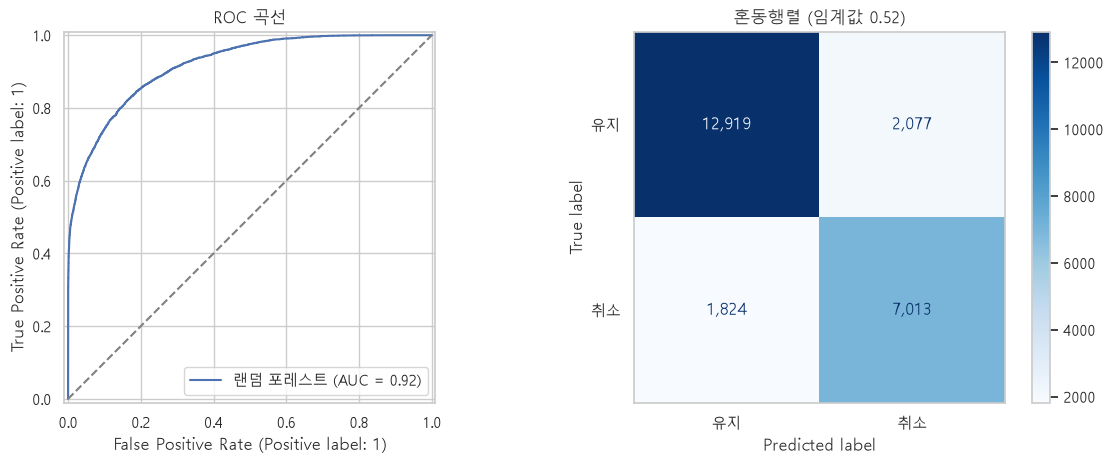

In [17]:
best = models["랜덤 포레스트"]

# 1) 학습 데이터를 다시 나눠 검증 데이터에서 임계값 선택
X_sub, X_val, y_sub, y_val = train_test_split(X_train, y_train, test_size=0.2, stratify=y_train, random_state=RANDOM_STATE)
val_proba = clone(best).fit(X_sub, y_sub).predict_proba(X_val)[:, 1]
precision, recall, thresholds = precision_recall_curve(y_val, val_proba)
f1 = 2 * precision[:-1] * recall[:-1] / np.maximum(precision[:-1] + recall[:-1], 1e-12)
threshold = float(thresholds[np.argmax(f1)])

# 2) 전체 학습 데이터로 다시 학습하고 테스트 데이터에서 평가
best.fit(X_train, y_train)
test_proba = best.predict_proba(X_test)[:, 1]
test_pred = (test_proba >= threshold).astype(int)
print(f"선택한 임계값 {threshold:.2f} · 테스트 ROC-AUC {roc_auc_score(y_test, test_proba):.3f}\n")
print(classification_report(y_test, test_pred, target_names=["유지", "취소"], digits=3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
RocCurveDisplay.from_predictions(y_test, test_proba, ax=axes[0], name="랜덤 포레스트")
axes[0].plot([0, 1], [0, 1], "--", color="gray")
axes[0].set_title("ROC 곡선")
ConfusionMatrixDisplay.from_predictions(y_test, test_pred, display_labels=["유지", "취소"], cmap="Blues", ax=axes[1], values_format=",")
axes[1].set_title(f"혼동행렬 (임계값 {threshold:.2f})")
axes[1].grid(False)
plt.tight_layout()
plt.show()

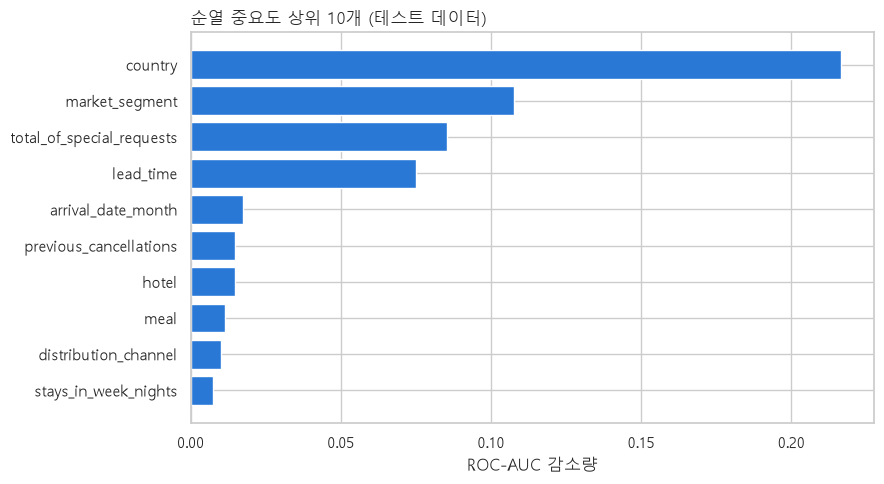

In [18]:
# 순열 중요도: 변수 하나를 무작위로 섞었을 때 ROC-AUC가 얼마나 떨어지는가
sample = X_test.sample(n=8000, random_state=RANDOM_STATE)
perm = permutation_importance(best, sample, y_test.loc[sample.index], scoring="roc_auc",
                              n_repeats=3, random_state=RANDOM_STATE, n_jobs=-1)
importance = pd.Series(perm.importances_mean, index=X.columns).sort_values().tail(10)

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(importance.index, importance.values, color=BLUE)
ax.set_xlabel("ROC-AUC 감소량")
ax.set_title("순열 중요도 상위 10개 (테스트 데이터)", loc="left")
plt.tight_layout()
plt.show()

예측에는 **국가 · 시장 세그먼트 · 특별 요청 수 · 리드타임**이 가장 많이 쓰였습니다. 탐색적 분석·통계 검정 결과와 같은 방향입니다. 다만 중요도가 높다고 해서 그 변수가 취소의 **원인**이라는 뜻은 아닙니다.

국가의 비중이 유독 커서 따로 점검했습니다. 국가 정보가 **예약 시점에 확정되는 값인지**는 데이터 설명만으로 확인할 수 없습니다. 그래서 국가를 뺀 모델도 함께 보고합니다.

In [19]:
top_countries = clean["country"].value_counts().head(5).index
display(rate_table(clean["country"].where(clean["country"].isin(top_countries), "기타"))
        .sort_values("예약수", ascending=False)[["예약수", "취소율"]].style.format({"예약수": "{:,}", "취소율": "{:.1%}"}))

no_country = [c for c in categorical_features if c != "country"]
model_wo = Pipeline([
    ("prep", ColumnTransformer([("num", StandardScaler(), numeric_features),
                                ("cat", OneHotEncoder(handle_unknown="ignore"), no_country)])),
    ("clf", RandomForestClassifier(n_estimators=200, min_samples_leaf=5, class_weight="balanced_subsample",
                                   n_jobs=-1, random_state=RANDOM_STATE)),
]).fit(X_train[numeric_features + no_country], y_train)
auc_wo = roc_auc_score(y_test, model_wo.predict_proba(X_test[numeric_features + no_country])[:, 1])
print(f"테스트 ROC-AUC · 국가 포함 {roc_auc_score(y_test, test_proba):.3f} → 국가 제외 {auc_wo:.3f}")

,예약수,취소율
country,,
PRT,"48,458",56.7%
기타,"32,352",27.6%
GBR,"12,115",20.2%
FRA,"10,400",18.6%
ESP,"8,559",25.4%
DEU,"7,281",16.7%


테스트 ROC-AUC · 국가 포함 0.919 → 국가 제외 0.886


**포르투갈(PRT)** 예약은 취소율이 56.7%로, 다른 상위 국가(17~25%)보다 훨씬 높습니다. 국가를 빼면 ROC-AUC가 0.919 → 0.886으로 내려가지만 크게 무너지지는 않습니다. 국가가 없어도 **리드타임·시장 세그먼트·특별 요청**만으로 취소를 상당 부분 구분할 수 있습니다. 다만 국가가 예약 시점 정보인지 확인되기 전까지는 **국가 제외 모델의 성능을 보수적인 기준**으로 삼는 것이 안전합니다.

---
## 5. 결론

In [20]:
def rate(name, label):
    return tables[name].loc[label, "취소율"]


key_findings = pd.DataFrame([
    ["리드타임", "366일+", rate("리드타임", "366일+"), "당일", rate("리드타임", "당일")],
    ["과거 취소 이력", "있음", binary_summary.loc["과거 취소 이력", "있음 취소율"], "없음", binary_summary.loc["과거 취소 이력", "없음 취소율"]],
    ["특별 요청", "0건", rate("특별 요청 건수", "0건"), "1건", rate("특별 요청 건수", "1건")],
    ["예약 변경", "0회", rate("예약 변경 횟수", "0회"), "1회", rate("예약 변경 횟수", "1회")],
    ["재방문 고객", "아님", binary_summary.loc["재방문 고객", "없음 취소율"], "재방문", binary_summary.loc["재방문 고객", "있음 취소율"]],
    ["시장 세그먼트", "Groups", rate("시장 세그먼트", "Groups"), "Direct", rate("시장 세그먼트", "Direct")],
], columns=["요인", "높은 쪽", "취소율 ①", "낮은 쪽", "취소율 ②"])
key_findings["차이(%p)"] = (key_findings["취소율 ①"] - key_findings["취소율 ②"]) * 100
key_findings.set_index("요인").style.format({"취소율 ①": "{:.1%}", "취소율 ②": "{:.1%}", "차이(%p)": "{:+.1f}"})

,높은 쪽,취소율 ①,낮은 쪽,취소율 ②,차이(%p)
요인,,,,,
리드타임,366일+,67.7%,당일,6.7%,+61.0
과거 취소 이력,있음,91.7%,없음,33.9%,+57.7
특별 요청,0건,47.8%,1건,22.0%,+25.7
예약 변경,0회,40.9%,1회,14.2%,+26.6
재방문 고객,아님,38.0%,재방문,13.1%,+25.0
시장 세그먼트,Groups,61.1%,Direct,15.3%,+45.8


### To Do

| 제안 | 근거 |
| :-- | :-- |
| **예약 후 30일 안에 리마인드·예약 확정 요청** | 취소 위험이 예약 직후 한 달에 가장 빠르게 증가 |
| **특별 요청·옵션 선택을 쉽게 만드는 예약 흐름** (조식·룸 업그레이드 1회 제안 등) | 요청·변경을 한 번이라도 한 고객은 취소율이 절반 이하 |
| **재방문 혜택**(다음 예약 할인 쿠폰) | 재방문 고객 취소율 약 13%로 매우 낮음 |
| **과거 취소 이력 고객에게 보증금·확정 절차 적용** | 과거 취소 이력이 있으면 약 92%가 다시 취소 |
| **Groups 세그먼트 관리 강화** (단체 예약 중간 확인) | 취소율 61%이면서 예약 수도 많음 |

### Not To Do

- **계절 할인·성수기 행사로 취소를 줄이려 하지 않습니다.** 도착 월에 따른 취소율 차이가 작습니다.
- **예약 변경을 어렵게 만들지 않습니다.** 변경한 고객이 오히려 덜 취소합니다.
- **예약 수가 적은 범주의 극단적인 취소율만 보고 정책을 바꾸지 않습니다.**
- **주차 요청 같은 체크인 이후 정보를 예측 변수로 쓰지 않습니다.**

### 한계

- 관찰 데이터라 상관관계일 뿐 **인과관계는 아닙니다.** 제안의 효과는 A/B 테스트로 검증해야 합니다.
- 객실 가격(ADR)·보증금 유형 같은 중요한 변수가 없어 설명력에 한계가 있습니다.
- 예약 ID가 없어 중복 행이 실제 중복 예약인지 확인할 수 없습니다.